# Turmeric Plant Disease Classification using a CNN

**Goal:** Design, train and analyse a Convolutional Neural Network that classifies turmeric images (leaf and rhizome) into healthy / diseased categories.

**Dataset folder structure (auto-detected):**
```
Turmeric Plant Disease/
├── Dry Leaf/
├── Healthy Leaf/
├── Leaf Blotch/
├── Rhizome Disease Root/
└── Rhizome Healthy Root/
```

**Pipeline:** Setup → EDA → Stratified split → tf.data pipeline → CNN design → Training → Evaluation & analysis → Save / Inference → (Optional) Transfer learning comparison

## 1. Setup

In [1]:
# Uncomment and run once if packages are missing
# %pip install tensorflow scikit-learn matplotlib seaborn pandas pillow

In [2]:
import os, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPUs: []


In [3]:
# ---------------- CONFIGURATION ----------------
# Path to the dataset folder. Relative to the notebook, or use an absolute path, e.g.
# DATA_DIR = r"C:\Users\you\Desktop\Turmeric Plant Disease"
DATA_DIR = "Turmeric Plant Disease"

IMG_SIZE   = (224, 224)
BATCH_SIZE = 32
EPOCHS     = 60
SEED       = 42
VAL_SIZE   = 0.15
TEST_SIZE  = 0.15
LR         = 1e-3

random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

## 2. Load file paths and explore the data

In [4]:
data_dir = Path(DATA_DIR)
assert data_dir.exists(), f"Folder not found: {data_dir.resolve()}  -> fix DATA_DIR above"

VALID_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
class_names = sorted([d.name for d in data_dir.iterdir() if d.is_dir()])
class_to_idx = {c: i for i, c in enumerate(class_names)}
NUM_CLASSES = len(class_names)

paths, labels = [], []
for c in class_names:
    for f in (data_dir / c).rglob("*"):
        if f.suffix.lower() in VALID_EXT:
            paths.append(str(f))
            labels.append(class_to_idx[c])

paths, labels = np.array(paths), np.array(labels)
print(f"Classes ({NUM_CLASSES}): {class_names}")
print(f"Total images: {len(paths)}")

Classes (5): ['Dry Leaf', 'Healthy Leaf', 'Leaf Blotch', 'Rhizome Disease Root', 'Rhizome Healthy Root']
Total images: 1063


Dry Leaf                203
Healthy Leaf            197
Leaf Blotch             199
Rhizome Disease Root    182
Rhizome Healthy Root    282
Name: count, dtype: int64


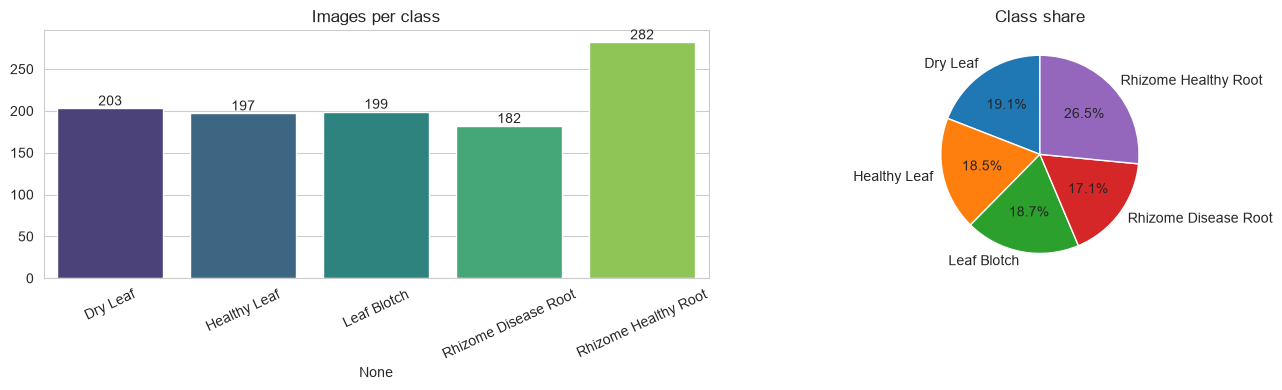

Imbalance ratio (max/min): 1.55


In [5]:
# Class distribution
counts = pd.Series(labels).map(lambda i: class_names[i]).value_counts().reindex(class_names)
print(counts)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(x=counts.index, y=counts.values, ax=ax[0], palette="viridis")
ax[0].set_title("Images per class"); ax[0].tick_params(axis="x", rotation=25)
for i, v in enumerate(counts.values):
    ax[0].text(i, v, str(v), ha="center", va="bottom")
ax[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90)
ax[1].set_title("Class share")
plt.tight_layout(); plt.show()

imbalance = counts.max() / counts.min()
print(f"Imbalance ratio (max/min): {imbalance:.2f}")

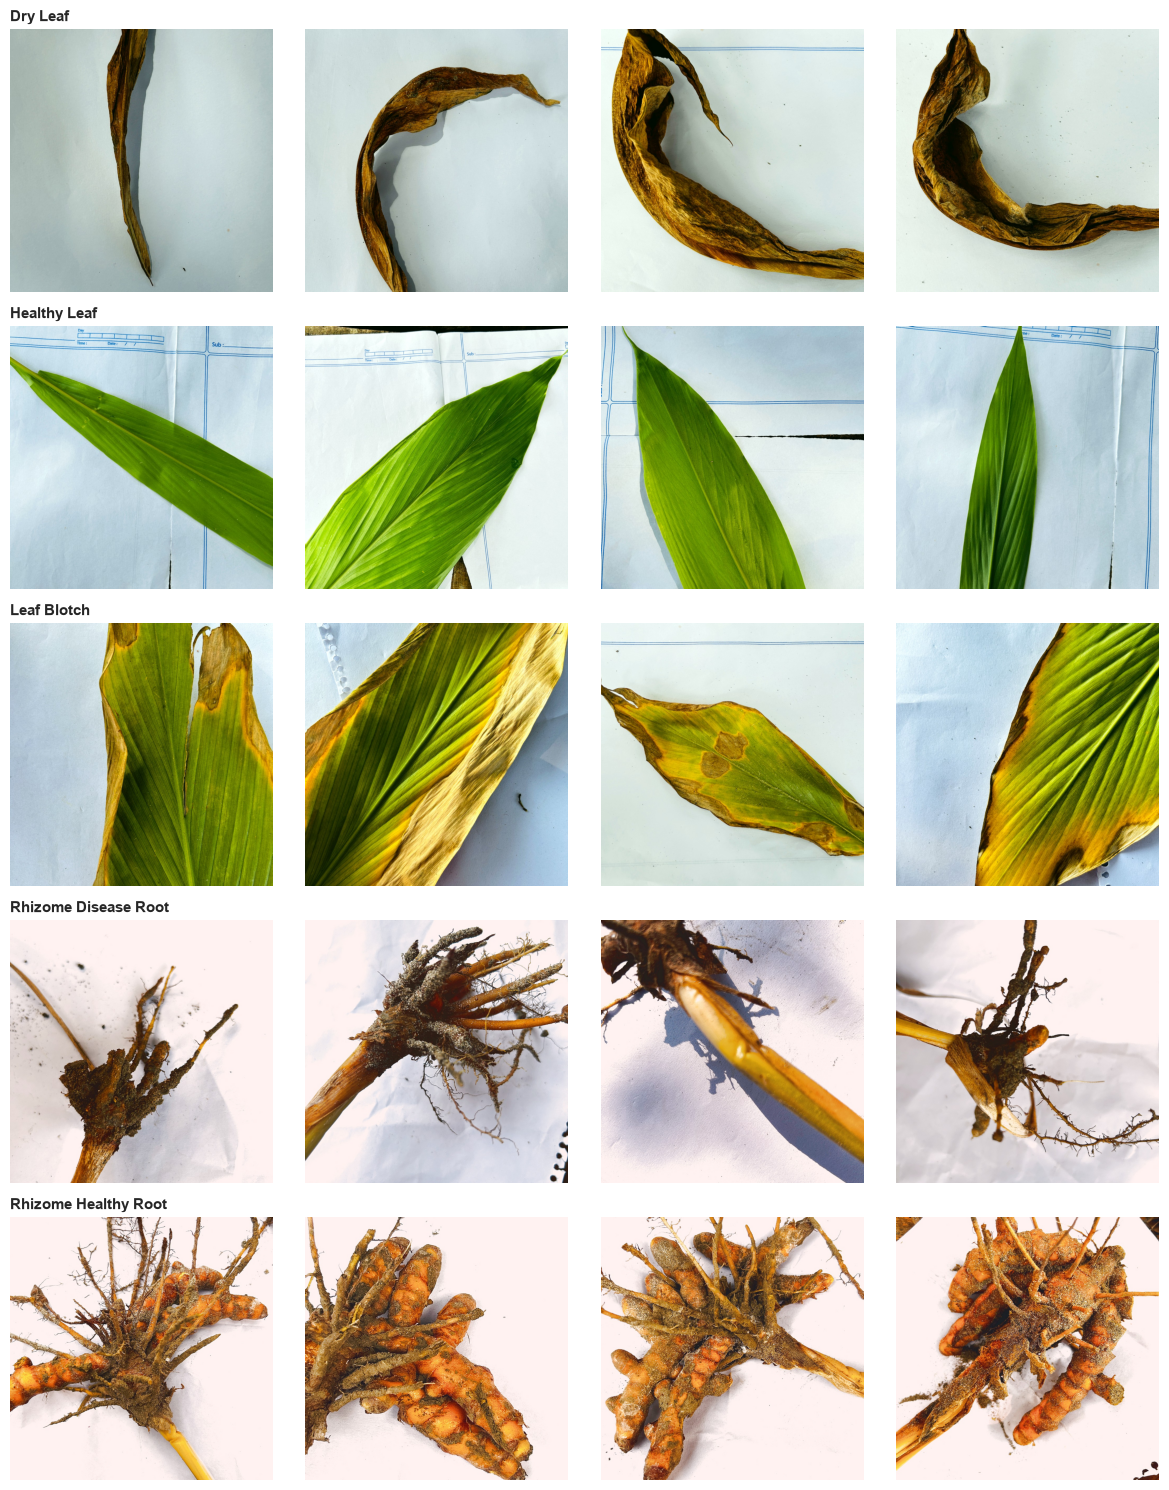

In [6]:
# Sample images from each class
n_per_class = 4
fig, axes = plt.subplots(NUM_CLASSES, n_per_class, figsize=(3 * n_per_class, 3 * NUM_CLASSES))
for r, c in enumerate(class_names):
    idxs = np.where(labels == class_to_idx[c])[0]
    for k, j in enumerate(np.random.choice(idxs, min(n_per_class, len(idxs)), replace=False)):
        axes[r, k].imshow(Image.open(paths[j]).convert("RGB"))
        axes[r, k].axis("off")
        if k == 0:
            axes[r, k].set_title(c, loc="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

In [7]:
# Image size / format check on a random sample
sample = np.random.choice(paths, min(300, len(paths)), replace=False)
sizes = []
for p in sample:
    with Image.open(p) as im:
        sizes.append(im.size)
sizes = pd.DataFrame(sizes, columns=["width", "height"])
print(sizes.describe().loc[["min", "mean", "max"]].round(0))

       width  height
min   1000.0  1000.0
mean  1000.0  1000.0
max   1000.0  1000.0


## 3. Stratified Train / Validation / Test split
Stratification keeps the class proportions identical in all three sets.

In [8]:
train_p, temp_p, train_y, temp_y = train_test_split(
    paths, labels, test_size=VAL_SIZE + TEST_SIZE, stratify=labels, random_state=SEED)
val_p, test_p, val_y, test_y = train_test_split(
    temp_p, temp_y, test_size=TEST_SIZE / (VAL_SIZE + TEST_SIZE), stratify=temp_y, random_state=SEED)

print(f"Train: {len(train_p)} | Val: {len(val_p)} | Test: {len(test_p)}")

Train: 744 | Val: 159 | Test: 160


## 4. Input pipeline (`tf.data`)

In [9]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img.set_shape((*IMG_SIZE, 3))
    return tf.cast(img, tf.float32), label

def make_ds(p, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((p, y))
    if training:
        ds = ds.shuffle(len(p), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(train_p, train_y, training=True)
val_ds   = make_ds(val_p, val_y)
test_ds  = make_ds(test_p, test_y)

# Class weights to handle any imbalance
cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_y)
class_weights = {i: w for i, w in enumerate(cw)}
print("Class weights:", {class_names[i]: round(w, 2) for i, w in class_weights.items()})

Class weights: {'Dry Leaf': np.float64(1.05), 'Healthy Leaf': np.float64(1.08), 'Leaf Blotch': np.float64(1.07), 'Rhizome Disease Root': np.float64(1.16), 'Rhizome Healthy Root': np.float64(0.76)}


## 5. Baseline: custom CNN (lighter, trained from scratch)
The first version collapsed to a single class (about 18% accuracy). Changes in this version:
- fewer filters (16 → 128) so the model fits a small dataset,
- gentler augmentation, a lower learning rate, and early stopping on **val_accuracy** with more patience.

In [10]:
def conv_block(x, filters, drop=0.0):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D()(x)
    if drop:
        x = layers.Dropout(drop)(x)
    return x

def build_cnn(input_shape=(*IMG_SIZE, 3), num_classes=NUM_CLASSES):
    inputs = keras.Input(shape=input_shape)
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomRotation(0.1)(x)
    x = layers.RandomZoom(0.1)(x)
    x = layers.Rescaling(1.0 / 255)(x)

    x = conv_block(x, 16)
    x = conv_block(x, 32)
    x = conv_block(x, 64)
    x = conv_block(x, 128, 0.3)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="turmeric_cnn")

cnn = build_cnn()
cnn.compile(optimizer=keras.optimizers.Adam(5e-4),
            loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn.summary()

Model: "turmeric_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 16)   │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 224, 224, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 32)   │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 56, 56, 64)     │             

 Total params: 312,117 (1.19 MB)

 Trainable params: 311,157 (1.19 MB)

 Non-trainable params: 960 (3.75 KB)

In [11]:
os.makedirs("outputs", exist_ok=True)

cnn_history = cnn.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS, class_weight=class_weights,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=15,
                                      restore_best_weights=True, mode="max"),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4,
                                          min_lr=1e-6, verbose=1),
    ],
)

Epoch 1/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 86s 3s/step - accuracy: 0.7715 - loss: 0.6688 - val_accuracy: 0.1887 - val_loss: 1.6860 - learning_rate: 5.0000e-04
Epoch 2/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 74s 3s/step - accuracy: 0.9247 - loss: 0.2638 - val_accuracy: 0.1887 - val_loss: 1.8260 - learning_rate: 5.0000e-04
Epoch 3/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 78s 3s/step - accuracy: 0.9476 - loss: 0.2075 - val_accuracy: 0.1887 - val_loss: 1.8973 - learning_rate: 5.0000e-04
Epoch 4/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 58s 2s/step - accuracy: 0.9583 - loss: 0.1479 - val_accuracy: 0.1887 - val_loss: 2.0617 - learning_rate: 5.0000e-04
Epoch 5/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9691 - loss: 0.1141
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
24/24 ━━━━━━━━━━━━━━━━━━━━ 56s 2s/step - accuracy: 0.9691 - loss: 0.1141 - val_accuracy: 0.1887 - val_loss: 2.7073 - learning_rate: 5.0000e-04
Epoch 6/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 56s 2s/step - accuracy: 0.9852 - loss: 0.077

## 6. Main model: transfer learning with MobileNetV2
Phase 1 trains only the new classification head on top of the frozen ImageNet backbone.
Phase 2 fine-tunes the top backbone layers at a very low learning rate.

In [12]:
def build_transfer(num_classes=NUM_CLASSES):
    base = keras.applications.MobileNetV2(input_shape=(*IMG_SIZE, 3),
                                          include_top=False, weights="imagenet")
    base.trainable = False

    inp = keras.Input(shape=(*IMG_SIZE, 3))
    x = layers.RandomFlip("horizontal_and_vertical")(inp)
    x = layers.RandomRotation(0.1)(x)
    x = layers.RandomZoom(0.1)(x)
    x = keras.applications.mobilenet_v2.preprocess_input(x)   # scales to [-1, 1]
    x = base(x, training=False)                               # keeps BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inp, out, name="turmeric_mobilenetv2"), base

tl_model, base = build_transfer()
tl_model.compile(optimizer=keras.optimizers.Adam(1e-3),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])

# Phase 1: train the head only
h1 = tl_model.fit(
    train_ds, validation_data=val_ds, epochs=15, class_weight=class_weights,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5,
                                             restore_best_weights=True, mode="max")],
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.6156 - loss: 0.9149 - val_accuracy: 0.8931 - val_loss: 0.3405
Epoch 2/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step - accuracy: 0.8844 - loss: 0.3216 - val_accuracy: 0.9686 - val_loss: 0.1710
Epoch 3/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 27s 1s/step - accuracy: 0.9462 - loss: 0.1746 - val_accuracy: 0.9937 - val_loss: 0.1169
Epoch 4/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 27s 1s/step - accuracy: 0.9610 - loss: 0.1424 - val_accuracy: 0.9937 - val_loss: 0.0997
Epoch 5/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - accuracy: 0.9731 - loss: 0.1088 - val_accuracy: 0.9937 - val_loss: 0.0849
Epoch 6/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.9637 - loss: 0.1096 - val_accuracy: 0.9937 - val_loss: 0.0588
Epoch 7/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - accuracy: 0.9812 - loss: 0.0779 - val_accuracy: 0.9937 - val_loss: 0.0586
Epoch 8/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - accuracy: 0.9879 

In [13]:
# Phase 2: fine-tune the last 30 backbone layers
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False

tl_model.compile(optimizer=keras.optimizers.Adam(1e-5),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])

h2 = tl_model.fit(
    train_ds, validation_data=val_ds, epochs=25, class_weight=class_weights,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=7,
                                      restore_best_weights=True, mode="max"),
        keras.callbacks.ModelCheckpoint("outputs/best_turmeric_mobilenetv2.keras",
                                        monitor="val_accuracy", save_best_only=True, mode="max"),
    ],
)

Epoch 1/25
24/24 ━━━━━━━━━━━━━━━━━━━━ 43s 1s/step - accuracy: 0.9099 - loss: 0.3305 - val_accuracy: 0.9937 - val_loss: 0.0952
Epoch 2/25
24/24 ━━━━━━━━━━━━━━━━━━━━ 33s 1s/step - accuracy: 0.9328 - loss: 0.2815 - val_accuracy: 1.0000 - val_loss: 0.0810
Epoch 3/25
24/24 ━━━━━━━━━━━━━━━━━━━━ 33s 1s/step - accuracy: 0.9476 - loss: 0.2103 - val_accuracy: 0.9937 - val_loss: 0.0702
Epoch 4/25
24/24 ━━━━━━━━━━━━━━━━━━━━ 33s 1s/step - accuracy: 0.9664 - loss: 0.1713 - val_accuracy: 0.9937 - val_loss: 0.0618
Epoch 5/25
24/24 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.9624 - loss: 0.1522 - val_accuracy: 0.9937 - val_loss: 0.0558
Epoch 6/25
24/24 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.9825 - loss: 0.1117 - val_accuracy: 1.0000 - val_loss: 0.0500
Epoch 7/25
24/24 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.9812 - loss: 0.1159 - val_accuracy: 1.0000 - val_loss: 0.0461
Epoch 8/25
24/24 ━━━━━━━━━━━━━━━━━━━━ 31s 1s/step - accuracy: 0.9772 - loss: 0.1108 - val_accuracy: 0.9937 - val_loss:

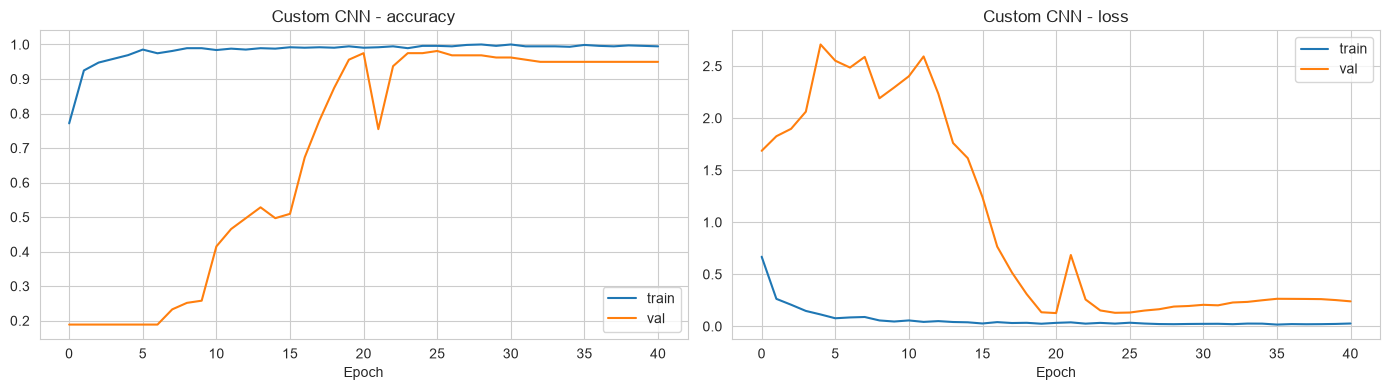

Custom CNN: best val_acc = 0.9811


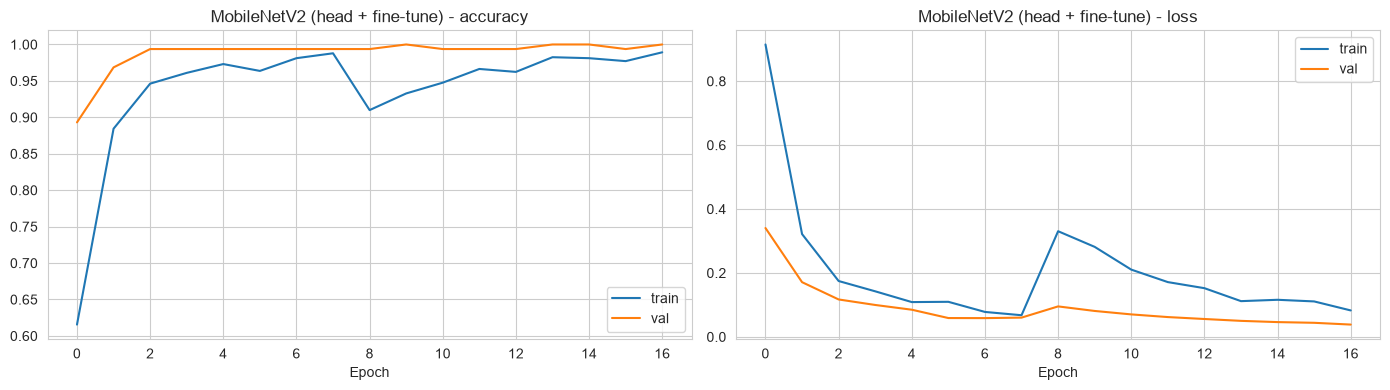

MobileNetV2 (head + fine-tune): best val_acc = 1.0000


In [14]:
# Training curves for both models
def curves(histories, title):
    h = pd.concat([pd.DataFrame(x.history) for x in histories], ignore_index=True)
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    ax[0].plot(h["accuracy"], label="train"); ax[0].plot(h["val_accuracy"], label="val")
    ax[0].set_title(f"{title} - accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].plot(h["loss"], label="train"); ax[1].plot(h["val_loss"], label="val")
    ax[1].set_title(f"{title} - loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()
    print(f"{title}: best val_acc = {h['val_accuracy'].max():.4f}")

curves([cnn_history], "Custom CNN")
curves([h1, h2], "MobileNetV2 (head + fine-tune)")

## 7. Evaluation on the held-out test set

In [15]:
def evaluate_model(m, name):
    loss, acc = m.evaluate(test_ds, verbose=0)
    probs = m.predict(test_ds, verbose=0)
    y_pred = probs.argmax(axis=1)
    print(f"===== {name} =====")
    print(f"Test loss: {loss:.4f} | Test accuracy: {acc:.4f}\n")
    print(classification_report(test_y, y_pred, target_names=class_names, digits=4))
    return dict(name=name, model=m, acc=acc, probs=probs, y_pred=y_pred)

res_cnn = evaluate_model(cnn, "Custom CNN")
res_tl  = evaluate_model(tl_model, "MobileNetV2")

comparison = pd.DataFrame([{"Model": r["name"], "Test accuracy": round(r["acc"], 4)} for r in (res_cnn, res_tl)])
display(comparison)

best_res = max((res_cnn, res_tl), key=lambda r: r["acc"])
best_model, probs, y_pred, y_true = best_res["model"], best_res["probs"], best_res["y_pred"], test_y
print("Best model for the analysis below:", best_res["name"])

===== Custom CNN =====
Test loss: 0.0218 | Test accuracy: 0.9937

                      precision    recall  f1-score   support

            Dry Leaf     1.0000    1.0000    1.0000        31
        Healthy Leaf     1.0000    1.0000    1.0000        29
         Leaf Blotch     1.0000    1.0000    1.0000        30
Rhizome Disease Root     1.0000    0.9630    0.9811        27
Rhizome Healthy Root     0.9773    1.0000    0.9885        43

            accuracy                         0.9938       160
           macro avg     0.9955    0.9926    0.9939       160
        weighted avg     0.9939    0.9938    0.9937       160

===== MobileNetV2 =====
Test loss: 0.0751 | Test accuracy: 1.0000

                      precision    recall  f1-score   support

            Dry Leaf     1.0000    1.0000    1.0000        31
        Healthy Leaf     1.0000    1.0000    1.0000        29
         Leaf Blotch     1.0000    1.0000    1.0000        30
Rhizome Disease Root     1.0000    1.0000    1.0000      

,Model,Test accuracy
0,Custom CNN,0.9937
1,MobileNetV2,1.0000


Best model for the analysis below: MobileNetV2


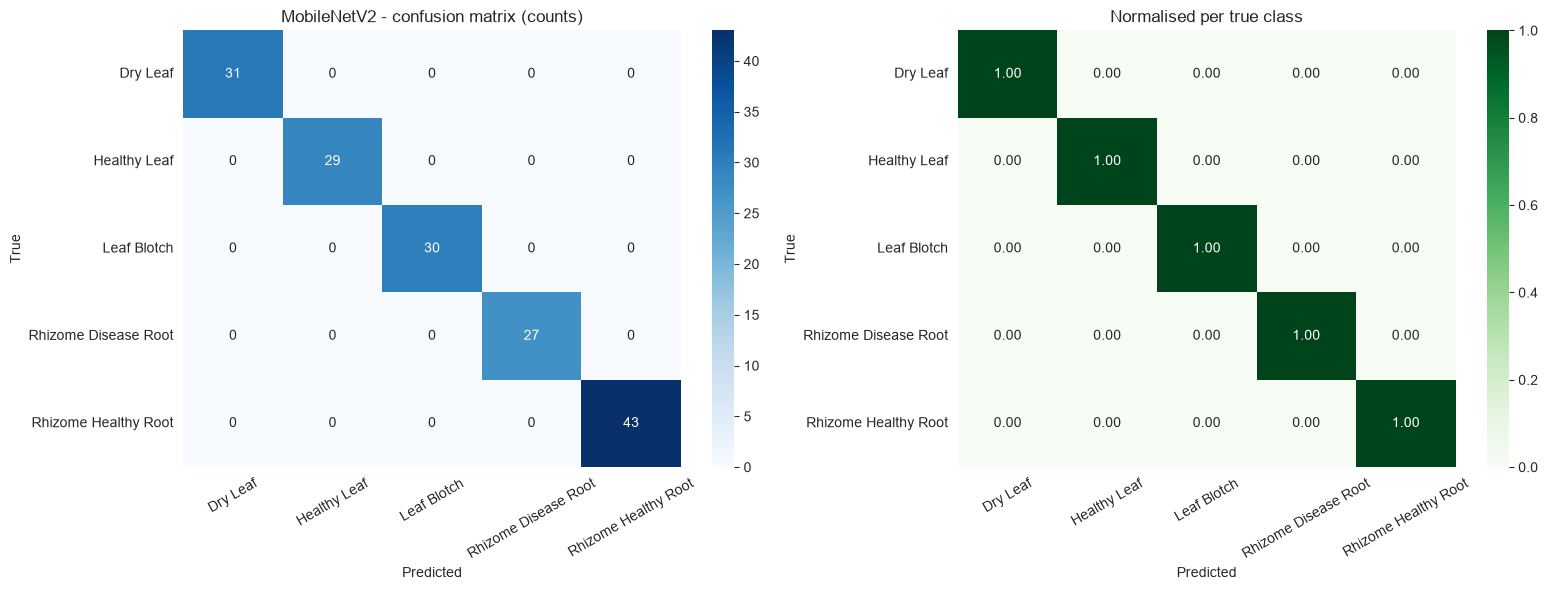

In [16]:
# Confusion matrices (counts and row-normalised) for the best model
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax[0])
ax[0].set_title(f"{best_res['name']} - confusion matrix (counts)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Greens", xticklabels=class_names, yticklabels=class_names, ax=ax[1])
ax[1].set_title("Normalised per true class")
for a in ax:
    a.set_xlabel("Predicted"); a.set_ylabel("True"); a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

## 8. Error analysis

In [17]:
per_class = pd.DataFrame({
    "class": class_names,
    "support": cm.sum(axis=1),
    "accuracy": np.diag(cm) / cm.sum(axis=1),
}).sort_values("accuracy")
display(per_class.round(3))

cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
pairs = [(class_names[i], class_names[j], cm_off[i, j])
         for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if cm_off[i, j] > 0]
pairs = sorted(pairs, key=lambda t: -t[2])[:5]
print("\nTop confusions (true -> predicted):")
for t, p, n in pairs:
    print(f"  {t}  ->  {p}: {n}")

,class,support,accuracy
0,Dry Leaf,31,1.0
1,Healthy Leaf,29,1.0
2,Leaf Blotch,30,1.0
3,Rhizome Disease Root,27,1.0
4,Rhizome Healthy Root,43,1.0



Top confusions (true -> predicted):


In [18]:
wrong = np.where(y_pred != y_true)[0]
print(f"Misclassified: {len(wrong)} / {len(y_true)}")

show = wrong[:12]
if len(show):
    cols = 4; rows = int(np.ceil(len(show) / cols))
    plt.figure(figsize=(4 * cols, 4 * rows))
    for k, i in enumerate(show):
        plt.subplot(rows, cols, k + 1)
        plt.imshow(Image.open(test_p[i]).convert("RGB")); plt.axis("off")
        plt.title(f"True: {class_names[y_true[i]]}\nPred: {class_names[y_pred[i]]} ({probs[i].max():.0%})",
                  fontsize=9, color="red")
    plt.tight_layout(); plt.show()

Misclassified: 0 / 160


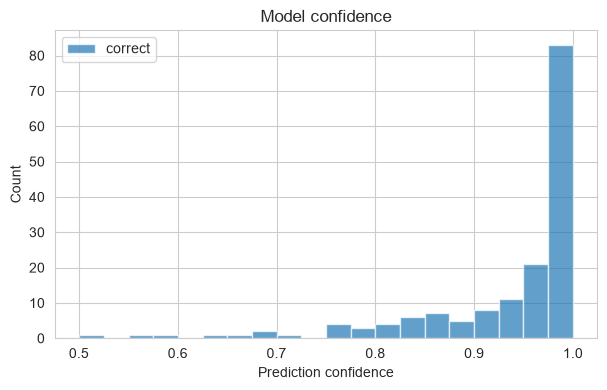

In [19]:
conf = probs.max(axis=1)
plt.figure(figsize=(7, 4))
plt.hist(conf[y_pred == y_true], bins=20, alpha=0.7, label="correct")
if len(wrong):
    plt.hist(conf[wrong], bins=20, alpha=0.7, label="incorrect")
plt.xlabel("Prediction confidence"); plt.ylabel("Count"); plt.legend(); plt.title("Model confidence")
plt.show()

## 9. Save the best model and predict on a new image

In [20]:
best_model.save("outputs/turmeric_best_model.keras")
with open("outputs/class_names.txt", "w") as f:
    f.write("\n".join(class_names))
print("Saved to ./outputs")

Saved to ./outputs


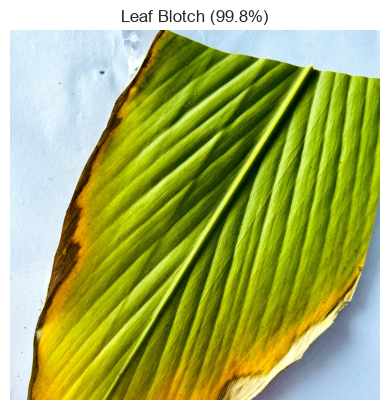

Leaf Blotch               99.82%
Healthy Leaf              0.14%
Dry Leaf                  0.03%


In [21]:
def predict_image(img_path, model=best_model, top_k=3):
    img = tf.io.decode_image(tf.io.read_file(img_path), channels=3, expand_animations=False)
    img = tf.cast(tf.image.resize(img, IMG_SIZE), tf.float32)
    p = model.predict(tf.expand_dims(img, 0), verbose=0)[0]
    order = p.argsort()[::-1][:top_k]
    plt.imshow(Image.open(img_path).convert("RGB")); plt.axis("off")
    plt.title(f"{class_names[order[0]]} ({p[order[0]]:.1%})")
    plt.show()
    for i in order:
        print(f"{class_names[i]:<25} {p[i]:.2%}")

predict_image(test_p[0])

## 10. Summary
- **Data:** images split 70/15/15 (stratified) into train/val/test.
- **Baseline:** a lightweight 4-block CNN trained from scratch.
- **Main model:** MobileNetV2 transfer learning (frozen head training, then fine-tuning).
- **Evaluation:** accuracy, precision/recall/F1, confusion matrices, misclassified images, confidence analysis.
- **Next steps:** Grad-CAM for explainability, larger image size, or EfficientNet backbones.